# 📊 Data Visualization — Supply Chain Dataset
**Course:** Data Visualization | **Semester 5**
**Dataset:** `SupplyChain Dataset.csv` — 1,500 orders (2024–2025), 24 columns
**Tool:** Python (Matplotlib · Seaborn · Plotly)

---

### Presentation Outline
1. Bar Charts (Vertical · Horizontal · Grouped · Stacked · 100% Stacked · Waterfall)
2. Bar Chart vs Histogram — Key Differences
3. Pie Charts (Standard · Donut · Sunburst · Polar Area)
4. Conclusion

> **Core Focus:** We are not just showing data — we are explaining **what each chart type is**, **how it differs from others**, and **why we picked it for this specific data**.

---
## ⚙️ Section 0 — Setup & Imports
We start by loading all the Python libraries we need and reading the dataset.

In [ ]:
# ── Standard libraries ───────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
import warnings
warnings.filterwarnings("ignore")

# ── Global style (clean academic look) ───────────────────────────────────────
plt.rcParams.update({
    "figure.dpi": 130,
    "figure.facecolor": "white",
    "axes.facecolor": "#f9f9f9",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelsize": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "font.family": "DejaVu Sans",
})

# Colour palette used throughout the notebook
PALETTE = ["#2196F3", "#FF9800", "#4CAF50", "#E91E63", "#9C27B0"]

print("✅ All libraries imported successfully.")

✅ All libraries imported successfully.


---
## 📂 Section 1 — Dataset Overview (EDA)
Before drawing any chart we take a quick look at the data:
what columns exist, what types they are, and what the numbers look like.

In [ ]:
# ── Load the dataset ─────────────────────────────────────────────────────────
df = pd.read_csv(r"SupplyChain Dataset.csv")

# Parse all date columns so Python treats them as dates, not text
for col in ["Order Date", "Shipment Date", "Delivery Date"]:
    df[col] = pd.to_datetime(df[col])

# Derived time columns used later
df["Order Year"]  = df["Order Date"].dt.year
df["Order Month"] = df["Order Date"].dt.month
df["Month Name"]  = df["Order Date"].dt.strftime("%b")

print(f"Dataset shape : {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Date range    : {df['Order Date'].min().date()}  →  {df['Order Date'].max().date()}")
print(f"Missing values: {df.isna().sum().sum()}")
print(f"Duplicates    : {df.duplicated().sum()}")
print()
print("Column names & data types:")
print(df.dtypes.to_string())

Dataset shape : 1,500 rows × 27 columns
Date range    : 2024-01-01  →  2025-12-31
Missing values: 0
Duplicates    : 0

Column names & data types:
Order ID                        int64
Order Date             datetime64[ns]
Shipment Date          datetime64[ns]
Delivery Date          datetime64[ns]
Customer ID                    object
Customer Region                object
Customer Country               object
Product ID                     object
Product Name                   object
Product Category               object
Supplier ID                    object
Supplier Name                  object
Supplier Region                object
Warehouse ID                   object
Warehouse Location             object
Transportation Mode            object
Order Quantity                  int64
Unit Price                    float64
Total Cost                    float64
Shipping Cost                 float64
Delivery Time Days              int64
Inventory Level                 int64
Order Status      

In [ ]:
# ── First 5 rows ─────────────────────────────────────────────────────────────
df.head()

,Order ID,Order Date,Shipment Date,Delivery Date,Customer ID,Customer Region,Customer Country,Product ID,Product Name,Product Category,...,Unit Price,Total Cost,Shipping Cost,Delivery Time Days,Inventory Level,Order Status,Profit,Order Year,Order Month,Month Name
0,100000,2024-04-12,2024-04-15,2024-04-24,C6734,Asia,China,P16265,Denim Jeans,Apparel,...,16.39,3671.36,18.82,9,2285,Delivered,668.08,2024,4,Apr
1,100001,2025-02-17,2025-02-22,2025-02-25,C7420,Africa,Egypt,P93104,Bluetooth Speaker,Electronics,...,264.66,85485.18,21.63,3,797,Cancelled,-21.20,2025,2,Feb
2,100002,2025-11-30,2025-12-05,2025-12-09,C2267,Africa,Kenya,P41551,Face Mask Box,Healthcare,...,78.52,10992.80,16.44,4,846,In Transit,2109.07,2025,11,Nov
3,100003,2024-08-29,2024-08-30,2024-09-03,C7235,Asia,Vietnam,P33483,Bottled Water Case,FMCG,...,27.28,11921.36,56.83,4,4314,Delivered,821.66,2024,8,Aug
4,100004,2025-01-24,2025-01-29,2025-02-17,C7873,North America,United States,P81211,Power Bank,Electronics,...,408.98,86294.78,8.79,19,319,Delivered,13786.48,2025,1,Jan


In [ ]:
# ── Numeric summary ──────────────────────────────────────────────────────────
df.describe(include="number").round(2)

,Order ID,Order Quantity,Unit Price,Total Cost,Shipping Cost,Delivery Time Days,Inventory Level,Profit,Order Year,Order Month
count,1500.00,1500.00,1500.00,1500.00,1500.00,1500.00,1500.00,1500.00,1500.00,1500.00
mean,100749.50,252.04,122.61,31071.05,22.40,9.36,1756.42,4838.14,2024.49,6.34
std,433.16,139.69,116.43,38075.68,13.33,6.33,1170.81,6610.79,0.50,3.41
min,100000.00,10.00,5.40,135.83,6.08,1.00,54.00,-247.46,2024.00,1.00
25%,100374.75,133.00,34.60,6282.10,13.26,4.00,835.75,632.06,2024.00,3.00
50%,100749.50,251.00,72.79,15765.84,17.16,8.00,1531.00,1952.89,2024.00,6.00
75%,101124.25,369.00,203.51,37603.76,26.57,13.00,2475.50,6206.16,2025.00,9.00
max,101499.00,500.00,449.81,215355.60,60.72,25.00,4980.00,38716.37,2025.00,12.00


In [ ]:
# ── Categorical summary ───────────────────────────────────────────────────────
cat_cols = ["Product Category", "Customer Region", "Transportation Mode",
            "Order Status", "Supplier Name", "Warehouse Location"]
for col in cat_cols:
    print(f"{col} ({df[col].nunique()} unique values):")
    print("  ", dict(df[col].value_counts()))
    print()

Product Category (5 unique values):
   {'FMCG': np.int64(328), 'Electronics': np.int64(310), 'Furniture': np.int64(304), 'Healthcare': np.int64(289), 'Apparel': np.int64(269)}

Customer Region (5 unique values):
   {'North America': np.int64(330), 'Middle East': np.int64(303), 'Asia': np.int64(301), 'Africa': np.int64(287), 'Europe': np.int64(279)}

Transportation Mode (4 unique values):
   {'Air': np.int64(380), 'Road': np.int64(379), 'Rail': np.int64(375), 'Sea': np.int64(366)}

Order Status (4 unique values):
   {'Delivered': np.int64(1236), 'In Transit': np.int64(123), 'Delayed': np.int64(88), 'Cancelled': np.int64(53)}

Supplier Name (10 unique values):
   {'Evergreen Partners': np.int64(182), 'BlueRiver Trading': np.int64(158), 'Pioneer Distribution': np.int64(158), 'Nova Industrial': np.int64(150), 'Summit Supply Co': np.int64(149), 'Zenith Procurement': np.int64(147), 'Crescent Logistics': np.int64(143), 'Atlas Sourcing': np.int64(142), 'Vertex Manufacturing': np.int64(137), 'O

---
## 📊 Section 2 — Bar Charts

### What is a Bar Chart?
A **Bar Chart** uses rectangular bars to compare values across **separate, named categories**.
Each bar represents one category; the length (or height) of the bar equals that category's value.

**When to use it:** When you want to compare a numeric measure (like sales, profit, or count)
across distinct groups that have **no natural order** (e.g., product types, regions, brands).

> **Key Rule:** Bar charts work with **categorical** data on one axis and a **numeric measure** on the other.
> The bars never touch each other because the categories are separate groups, not a continuous range.

### 2.1 Vertical Bar Chart
**Definition:** Bars run **upward from the bottom**. The x-axis holds the category names and
the y-axis holds the numeric value. This is the most common and intuitive type.

**Why Vertical?** We use a vertical bar chart when category labels are **short** and there are
**few categories (≤ 8)**. The eye naturally reads height differences top-to-bottom, making it
easy to spot the tallest bar instantly.

**Data used:** Total **Profit** by **Product Category** (5 categories, 1,500 orders, 2024–2025)

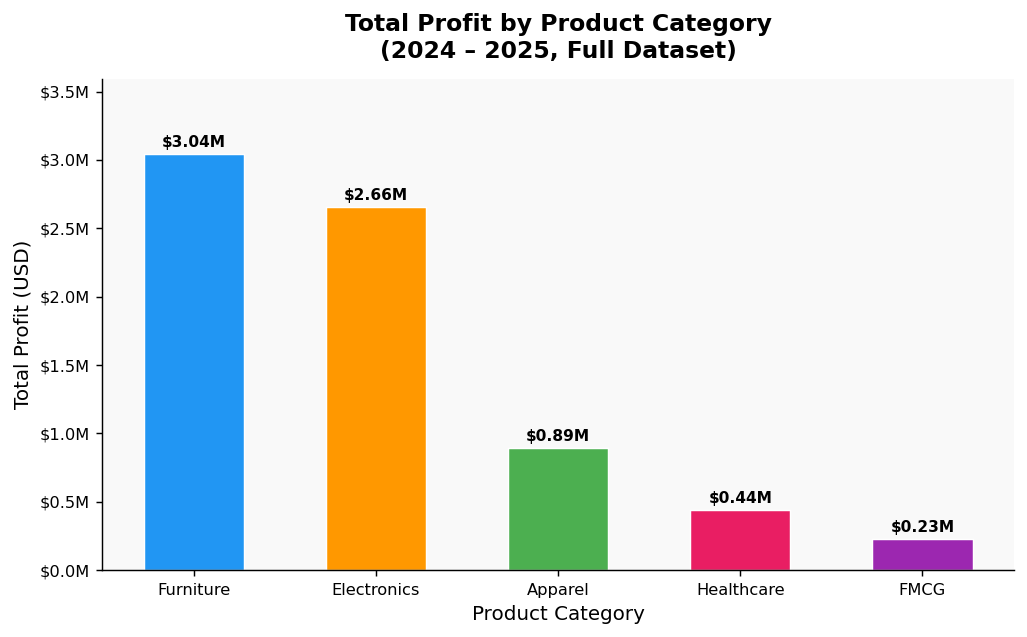

Chart saved → chart_2_1_vertical_bar.png


In [ ]:
# ── Aggregate ────────────────────────────────────────────────────────────────
cat_profit = (
    df.groupby("Product Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)
cat_profit["Profit_M"] = cat_profit["Profit"] / 1_000_000   # millions for labels

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    cat_profit["Product Category"],
    cat_profit["Profit"],
    color=PALETTE,
    width=0.55,
    edgecolor="white",
    linewidth=0.8,
)

# Value labels on top of each bar
for bar, val in zip(bars, cat_profit["Profit"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 30_000,
        f"${val/1e6:.2f}M",
        ha="center", va="bottom", fontsize=8.5, fontweight="bold"
    )

ax.set_title("Total Profit by Product Category\n(2024 – 2025, Full Dataset)", pad=12)
ax.set_xlabel("Product Category")
ax.set_ylabel("Total Profit (USD)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1e6:.1f}M"))
ax.set_ylim(0, cat_profit["Profit"].max() * 1.18)
ax.set_facecolor("#f9f9f9")
plt.tight_layout()
plt.savefig("chart_2_1_vertical_bar.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved → chart_2_1_vertical_bar.png")

#### 📌 Interpretation
- **Furniture** is the most profitable category at **\$3.04M** — nearly **42%** of total profit.
- **Electronics** comes second at **\$2.66M**.
- **FMCG** (Fast-Moving Consumer Goods like water, shampoo) earns the least at **\$226.7K** — only 3% of total.
- **Why this chart?** We have exactly 5 short category names and one numeric measure (Profit).
  Bars sorted from tallest to shortest let the audience instantly rank categories without reading numbers.

### 2.2 Horizontal Bar Chart
**Definition:** Bars run **sideways from left to right**. The y-axis holds the category names
and the x-axis holds the numeric value.

**Why Horizontal?** We switch to horizontal bars when category labels are **long** or when there
are **many categories (> 8)**. Long labels on a vertical chart overlap and become unreadable.
Turning the chart sideways gives each label its own row, making everything legible.

**Data used:** Total **Orders** by **Customer Country** (27 countries, sorted by order count)

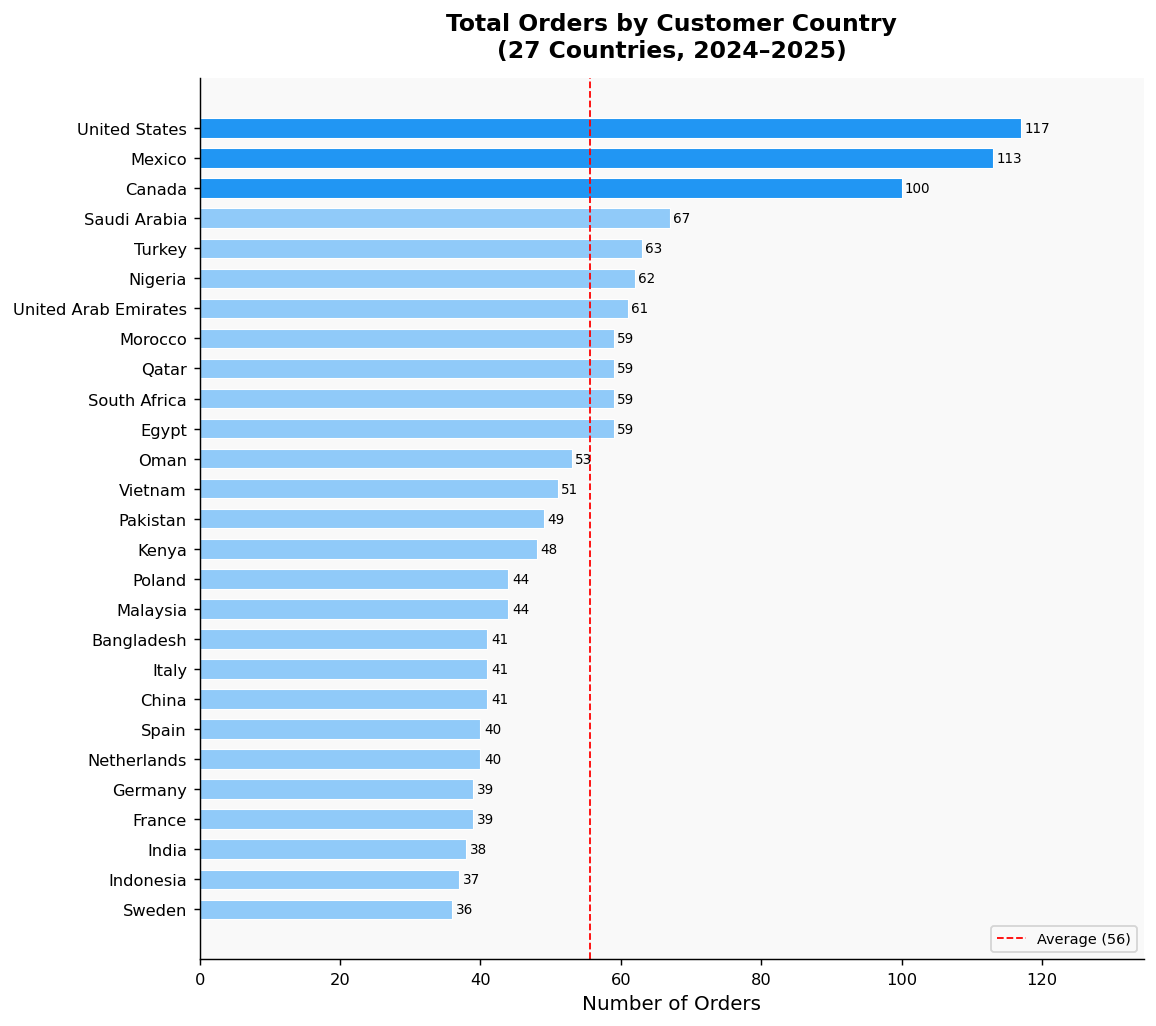

Chart saved → chart_2_2_horizontal_bar.png


In [ ]:
# ── Aggregate ────────────────────────────────────────────────────────────────
country_orders = (
    df.groupby("Customer Country")["Order ID"]
    .count()
    .sort_values(ascending=True)       # ascending so largest is at the top
    .reset_index(name="Orders")
)

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 8))

colors = ["#2196F3" if v >= 80 else "#90CAF9" for v in country_orders["Orders"]]

bars = ax.barh(
    country_orders["Customer Country"],
    country_orders["Orders"],
    color=colors,
    height=0.65,
    edgecolor="white",
    linewidth=0.6,
)

# Value labels at the end of each bar
for bar, val in zip(bars, country_orders["Orders"]):
    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        str(val),
        va="center", fontsize=7.5
    )

ax.set_title("Total Orders by Customer Country\n(27 Countries, 2024–2025)", pad=12)
ax.set_xlabel("Number of Orders")
ax.set_ylabel("")
ax.set_xlim(0, country_orders["Orders"].max() * 1.15)
ax.axvline(country_orders["Orders"].mean(), color="red", linestyle="--",
           linewidth=1, label=f"Average ({country_orders['Orders'].mean():.0f})")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("chart_2_2_horizontal_bar.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved → chart_2_2_horizontal_bar.png")

#### 📌 Interpretation
- **USA, Mexico, and Canada** lead with the most orders (100–117 each) — North America is
  clearly the most active customer region.
- **Sweden, Indonesia, India, France, and Germany** are at the bottom (36–39 orders each).
- The red dashed line is the average orders per country (~55). Countries above it are high-volume markets.
- **Why this chart?** 27 country names are too long and too many to fit on a vertical bar chart.
  Turning the chart horizontal gives each country its own labeled row — the audience can read
  every name without straining.

### 2.3 Grouped (Clustered) Bar Chart
**Definition:** Multiple bars are placed **side-by-side** within each category group.
Each colour represents a sub-category. The bars are grouped so you can compare both
*across groups* and *within each group* at a glance.

**Why Grouped?** When you have **two categorical dimensions** and want to compare them
simultaneously. A single bar per group would hide the sub-category difference.

**Data used:** Average **Delivery Time (Days)** by **Transportation Mode** (4 modes)
grouped by **Product Category** (5 categories)

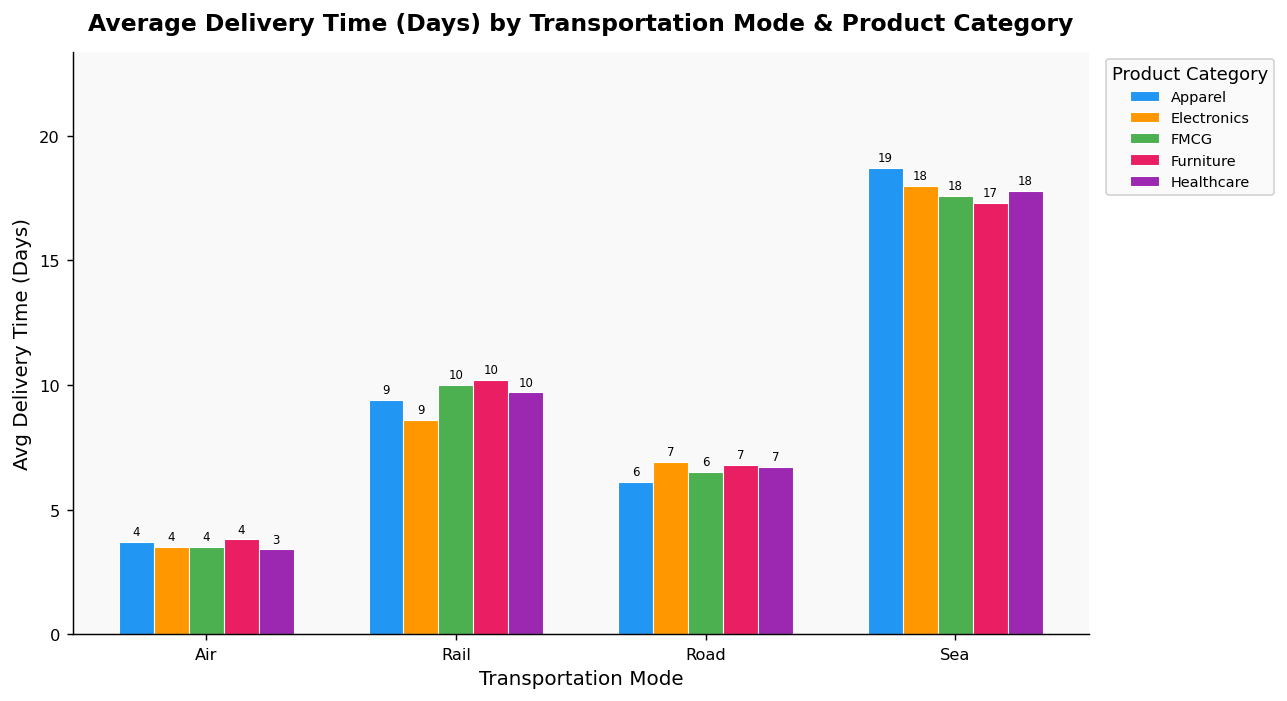

Chart saved → chart_2_3_grouped_bar.png


In [ ]:
# ── Aggregate ────────────────────────────────────────────────────────────────
grp = (
    df.groupby(["Transportation Mode", "Product Category"])["Delivery Time Days"]
    .mean()
    .round(1)
    .reset_index()
)

modes = grp["Transportation Mode"].unique()
categories = sorted(grp["Product Category"].unique())
x = np.arange(len(modes))
n_cats = len(categories)
width = 0.14          # width of each individual bar
offsets = np.linspace(-(n_cats-1)/2 * width, (n_cats-1)/2 * width, n_cats)

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5.5))

for i, (cat, offset, color) in enumerate(zip(categories, offsets, PALETTE)):
    vals = [
        grp.loc[(grp["Transportation Mode"] == m) &
                (grp["Product Category"] == cat), "Delivery Time Days"].values
        for m in modes
    ]
    vals = [v[0] if len(v) > 0 else 0 for v in vals]
    bars = ax.bar(x + offset, vals, width, label=cat, color=color,
                  edgecolor="white", linewidth=0.6)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.15,
                f"{val:.0f}", ha="center", va="bottom", fontsize=6.5)

ax.set_title("Average Delivery Time (Days) by Transportation Mode & Product Category",
             pad=12)
ax.set_xlabel("Transportation Mode")
ax.set_ylabel("Avg Delivery Time (Days)")
ax.set_xticks(x)
ax.set_xticklabels(modes)
ax.legend(title="Product Category", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_ylim(0, grp["Delivery Time Days"].max() * 1.25)
plt.tight_layout()
plt.savefig("chart_2_3_grouped_bar.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved → chart_2_3_grouped_bar.png")

#### 📌 Interpretation
- **Sea** has the longest delivery times (~17–20 days) across **all** product categories —
  makes sense physically (ships are slow).
- **Air** is consistently fastest (~3–4 days), regardless of what product is being shipped.
- Within each mode, delivery times are similar across product categories — meaning the
  transport method matters far more than the product type.
- **Why this chart?** We have two dimensions: Transportation Mode AND Product Category.
  A grouped bar chart lets us compare all combinations in one view.
  A simple bar chart could only show one dimension at a time.

### 2.4 Stacked Bar Chart
**Definition:** Bars are split into coloured segments that are **stacked on top of each other**.
The total bar height shows the overall value; each colour segment shows one sub-category's contribution.

**Why Stacked?** When you want to see **both the total AND the breakdown** in one chart.
Unlike grouped bars, stacked bars emphasise the total. The trade-off is that comparing
individual segments is harder (segments don't all start from zero).

**Data used:** Total **Profit** by **Customer Region** (5 regions), broken down by
**Product Category** (5 categories)

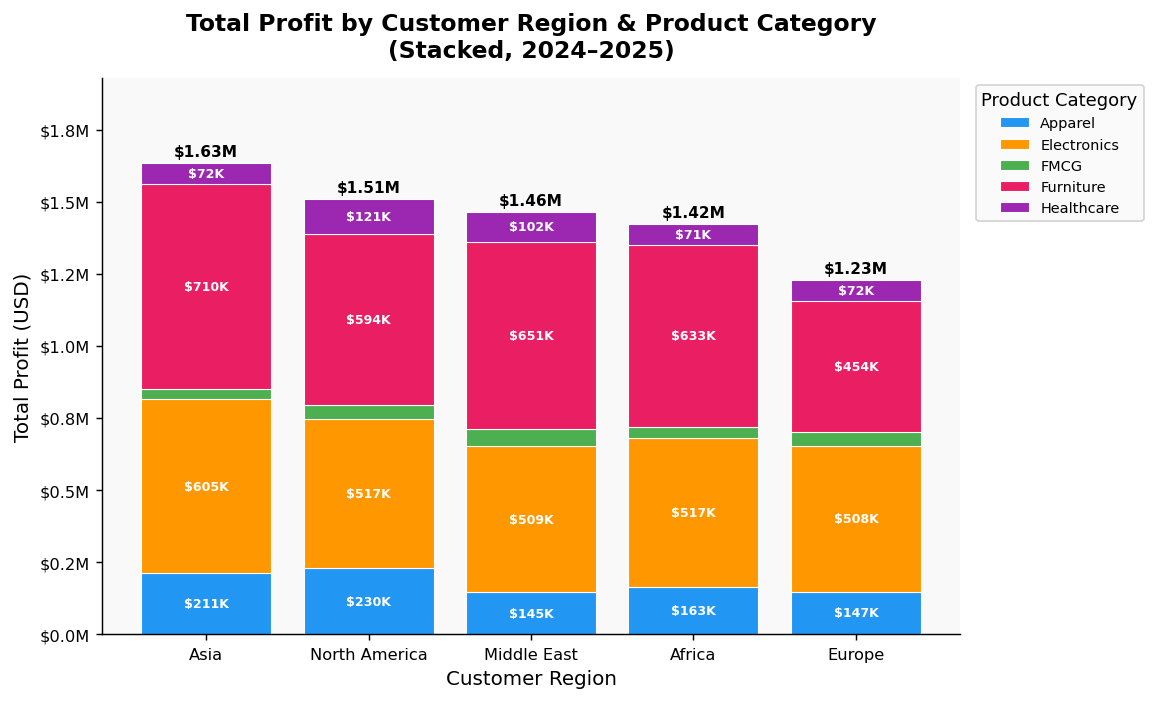

Chart saved → chart_2_4_stacked_bar.png


In [ ]:
# ── Aggregate ────────────────────────────────────────────────────────────────
stk = (
    df.groupby(["Customer Region", "Product Category"])["Profit"]
    .sum()
    .unstack("Product Category")
    .fillna(0)
)
# Sort regions by total profit (highest at top of chart)
stk = stk.loc[stk.sum(axis=1).sort_values(ascending=False).index]

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5.5))

bottom = np.zeros(len(stk))
for cat, color in zip(stk.columns, PALETTE):
    bars = ax.bar(stk.index, stk[cat], bottom=bottom,
                  label=cat, color=color, edgecolor="white", linewidth=0.6)
    # Only label segments that are large enough to read
    for bar, val in zip(bars, stk[cat]):
        if val > 60_000:
            ax.text(bar.get_x() + bar.get_width()/2,
                    bar.get_y() + bar.get_height()/2,
                    f"${val/1e3:.0f}K",
                    ha="center", va="center", fontsize=7, color="white", fontweight="bold")
    bottom += stk[cat].values

# Total label on top of each bar
for i, (region, total) in enumerate(stk.sum(axis=1).items()):
    ax.text(i, total + 15_000, f"${total/1e6:.2f}M",
            ha="center", va="bottom", fontsize=8.5, fontweight="bold")

ax.set_title("Total Profit by Customer Region & Product Category\n(Stacked, 2024–2025)",
             pad=12)
ax.set_xlabel("Customer Region")
ax.set_ylabel("Total Profit (USD)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1e6:.1f}M"))
ax.legend(title="Product Category", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_ylim(0, stk.sum(axis=1).max() * 1.18)
plt.tight_layout()
plt.savefig("chart_2_4_stacked_bar.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved → chart_2_4_stacked_bar.png")

#### 📌 Interpretation
- **Asia** has the highest total profit (~\$1.63M), narrowly ahead of **North America** (~\$1.51M).
- **Furniture** (blue) is the dominant segment in every region — it drives the most profit everywhere.
- **FMCG** (orange) is a tiny sliver in every region, barely visible — confirming it has the lowest margins.
- **Why this chart?** We want to show two things at once: (1) which region earns the most total profit
  and (2) how that profit is split across product categories. Stacked bars answer both questions in one view.
  A simple bar chart would lose the category breakdown; grouped bars would lose the total.

### 2.5 100% Stacked Bar Chart
**Definition:** Every bar is stretched to exactly **100%**. The coloured segments now show
**proportions (percentages)** rather than raw values. All bars are the same height.

**Why 100% Stacked?** When you want to compare the **share or mix** of sub-categories
across groups — and the total size of each group does NOT matter. It makes proportional
differences very clear but hides absolute values entirely.

**Data used:** **Order Status** share (Delivered / In Transit / Delayed / Cancelled)
across each **Transportation Mode** — showing which mode is most reliable.

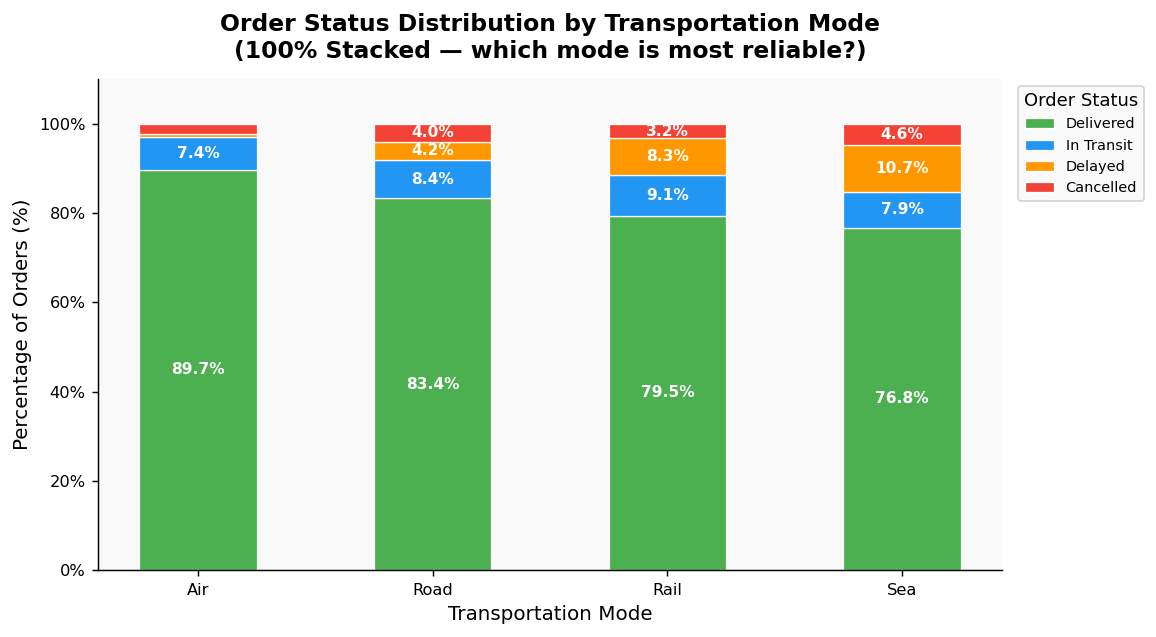

Chart saved → chart_2_5_100pct_stacked_bar.png


In [ ]:
# ── Aggregate ────────────────────────────────────────────────────────────────
pct = (
    df.groupby(["Transportation Mode", "Order Status"])["Order ID"]
    .count()
    .unstack("Order Status")
    .fillna(0)
)
pct_norm = pct.div(pct.sum(axis=1), axis=0) * 100   # convert to %

# Fix colour order for status (green = good, red = bad)
status_order  = ["Delivered", "In Transit", "Delayed", "Cancelled"]
status_colors = ["#4CAF50", "#2196F3", "#FF9800", "#F44336"]
pct_norm = pct_norm[status_order]

# Sort rows by "Delivered %" descending (most reliable first)
pct_norm = pct_norm.sort_values("Delivered", ascending=False)

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5))

bottom = np.zeros(len(pct_norm))
for status, color in zip(status_order, status_colors):
    vals = pct_norm[status].values
    bars = ax.bar(pct_norm.index, vals, bottom=bottom,
                  label=status, color=color, edgecolor="white", linewidth=0.7, width=0.5)
    for bar, val in zip(bars, vals):
        if val > 3:
            ax.text(bar.get_x() + bar.get_width()/2,
                    bar.get_y() + bar.get_height()/2,
                    f"{val:.1f}%",
                    ha="center", va="center", fontsize=8.5,
                    color="white", fontweight="bold")
    bottom += vals

ax.set_title("Order Status Distribution by Transportation Mode\n"
             "(100% Stacked — which mode is most reliable?)", pad=12)
ax.set_xlabel("Transportation Mode")
ax.set_ylabel("Percentage of Orders (%)")
ax.set_ylim(0, 110)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}%"))
ax.legend(title="Order Status", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig("chart_2_5_100pct_stacked_bar.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved → chart_2_5_100pct_stacked_bar.png")

#### 📌 Interpretation
- **Air** is the most reliable mode: **89.7% Delivered** and only **0.5% Delayed** — the best performance.
- **Sea** is the least reliable: only **76.8% Delivered** and **10.7% Delayed** — the worst delay rate.
- **Rail** has the highest Cancelled rate (~9%).
- **Why this chart?** We care about *proportions*, not absolute order counts. Each transport mode
  carries different numbers of orders, so raw counts would be misleading. Stretching every bar to 100%
  puts all modes on an equal footing and makes the reliability gap crystal clear.

### 2.6 Waterfall Chart
**Definition:** A Waterfall chart shows how a **starting value changes step-by-step** to reach
a final value. Green bars are increases; red bars are decreases; grey or blue bars are totals.
The chart looks like stepping stones — each bar "floats" at the level where the previous one ended.

**Why Waterfall?** When you want to explain **what drove a change** between two values.
It answers the question *"We started at X and ended at Y — what caused the difference?"*
Unlike a simple bar chart (which just shows the start and end), a Waterfall shows each contributing factor.

**Data used:** Total **Profit** change from **2024 to 2025** broken down by **Product Category**
— showing which categories grew and which declined.

In [ ]:
# ── Aggregate ────────────────────────────────────────────────────────────────
yearly = (
    df.groupby(["Order Year", "Product Category"])["Profit"]
    .sum()
    .unstack("Order Year")
    .fillna(0)
)
yearly.columns = [2024, 2025]
yearly["Change"] = yearly[2025] - yearly[2024]
yearly = yearly.sort_values("Change")          # smallest change first

total_2024 = yearly[2024].sum()
total_2025 = yearly[2025].sum()
overall_change = total_2025 - total_2024

# ── Build Waterfall data ─────────────────────────────────────────────────────
labels   = ["2024 Total"] + list(yearly.index) + ["2025 Total"]
measures = ["absolute"] + ["relative"] * len(yearly) + ["absolute"]
values   = [total_2024]  + list(yearly["Change"]) + [total_2025]

text_labels = [f"${v/1e6:.2f}M" for v in values]

fig = go.Figure(go.Waterfall(
    name="Profit Bridge",
    orientation="v",
    measure=measures,
    x=labels,
    y=values,
    text=text_labels,
    textposition="outside",
    increasing  = {"marker": {"color": "#4CAF50"}},
    decreasing  = {"marker": {"color": "#F44336"}},
    totals      = {"marker": {"color": "#2196F3"}},
    connector   = {"line": {"color": "#bdbdbd", "dash": "dot", "width": 1}},
))

fig.update_layout(
    title={
        "text": "Profit Bridge: 2024 → 2025 by Product Category<br>"
                "<sup>Green = growth &nbsp;|&nbsp; Red = decline &nbsp;|&nbsp; Blue = total</sup>",
        "x": 0.5, "xanchor": "center"
    },
    yaxis_title="Total Profit (USD)",
    yaxis_tickformat="$,.0f",
    plot_bgcolor="white",
    paper_bgcolor="white",
    font={"family": "Arial", "size": 12},
    height=500,
    showlegend=False,
    margin=dict(t=100, b=60),
)
fig.show()

#### 📌 Interpretation
- We started 2024 with **\$3.73M** in total profit.
- **Furniture dropped by \$274K** (biggest red bar) — the main reason 2025 was worse.
- **Healthcare** and **FMCG** also declined (smaller red bars).
- **Electronics (+\$61.7K)** and **Apparel (+\$59.2K)** both grew (green bars).
- Despite the growth in two categories, the Furniture decline dragged the total down to **\$3.52M** in 2025.
- **Why this chart?** A simple bar chart showing 2024 vs 2025 total profit would only say "profit dropped."
  The Waterfall chart shows *why* it dropped — Furniture is the culprit — and shows that two
  categories actually improved. That is a much richer story.

---
## 📊 Section 3 — Bar Chart vs. Histogram

### What is a Histogram?
A **Histogram** looks like a bar chart but it is fundamentally different.
It shows the **distribution** of a **single numeric variable** by grouping values into ranges
(called "bins") and counting how many data points fall in each range.

### Key Differences

| Feature | Bar Chart | Histogram |
|---|---|---|
| **Data type** | Categorical (named groups) | Numeric (continuous values) |
| **Gaps between bars** | YES — categories are separate | NO — bars touch (ranges are continuous) |
| **Bar order** | Can be rearranged freely | MUST follow numeric order |
| **Purpose** | Compare values across groups | Show the shape/spread of one variable |

We now show a Histogram alongside a Bar Chart so the differences are clear.

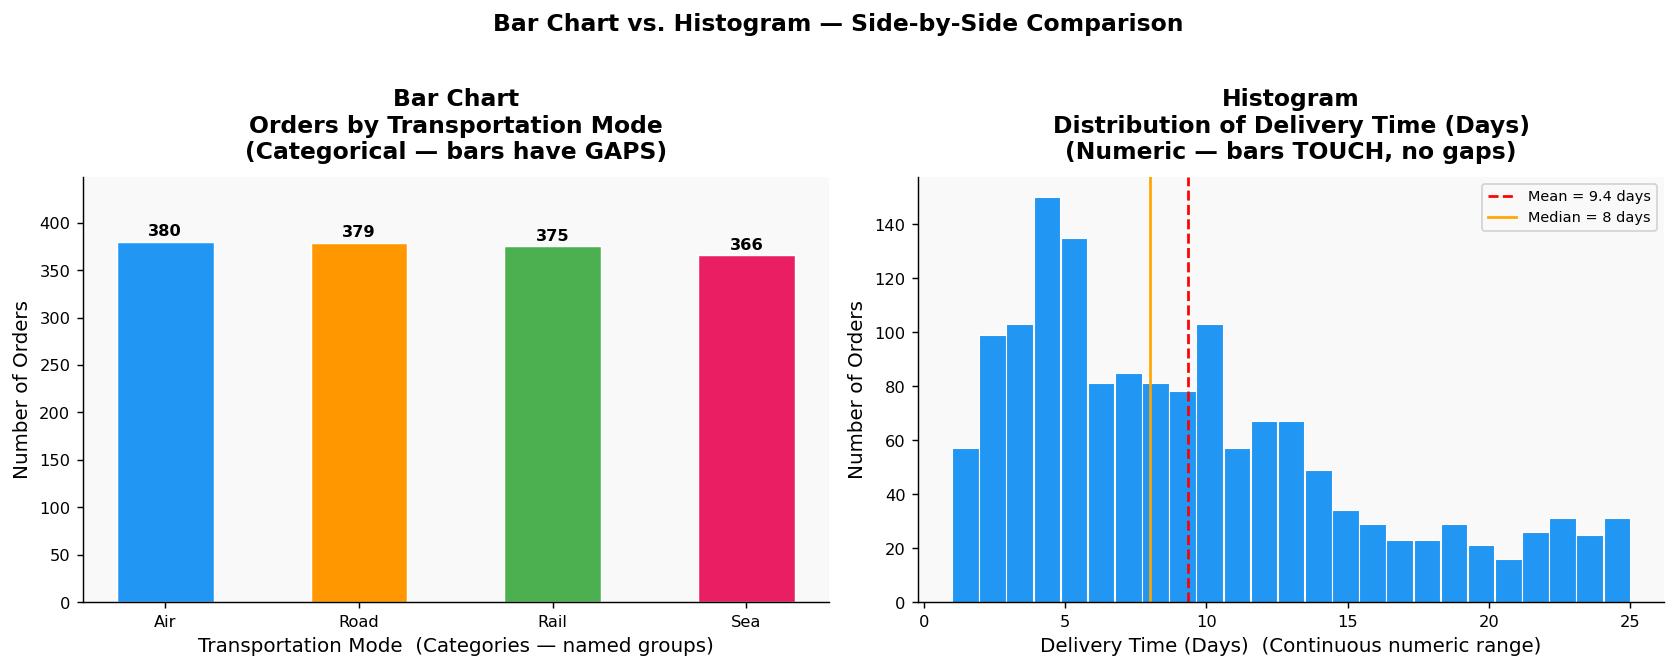

Chart saved → chart_3_bar_vs_histogram.png


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ── LEFT: Bar Chart (categorical) ────────────────────────────────────────────
mode_orders = df["Transportation Mode"].value_counts().reset_index()
mode_orders.columns = ["Mode", "Orders"]
mode_orders = mode_orders.sort_values("Orders", ascending=False)

axes[0].bar(mode_orders["Mode"], mode_orders["Orders"],
            color=PALETTE[:4], width=0.5, edgecolor="white", linewidth=0.8)
for bar, val in zip(axes[0].patches, mode_orders["Orders"]):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 3, str(val),
                 ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[0].set_title("Bar Chart\nOrders by Transportation Mode\n(Categorical — bars have GAPS)", pad=10)
axes[0].set_xlabel("Transportation Mode  (Categories — named groups)")
axes[0].set_ylabel("Number of Orders")
axes[0].set_ylim(0, mode_orders["Orders"].max() * 1.18)

# ── RIGHT: Histogram (numeric) ───────────────────────────────────────────────
axes[1].hist(df["Delivery Time Days"], bins=25, color="#2196F3",
             edgecolor="white", linewidth=0.6, rwidth=0.98)
axes[1].set_title("Histogram\nDistribution of Delivery Time (Days)\n(Numeric — bars TOUCH, no gaps)", pad=10)
axes[1].set_xlabel("Delivery Time (Days)  (Continuous numeric range)")
axes[1].set_ylabel("Number of Orders")

# Annotate mean and median
mean_val   = df["Delivery Time Days"].mean()
median_val = df["Delivery Time Days"].median()
axes[1].axvline(mean_val,   color="red",    linestyle="--", linewidth=1.5, label=f"Mean = {mean_val:.1f} days")
axes[1].axvline(median_val, color="orange", linestyle="-",  linewidth=1.5, label=f"Median = {median_val:.0f} days")
axes[1].legend(fontsize=8)

plt.suptitle("Bar Chart vs. Histogram — Side-by-Side Comparison",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("chart_3_bar_vs_histogram.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved → chart_3_bar_vs_histogram.png")

#### 📌 Interpretation

**Bar Chart (left):**
- Each bar represents one named group (Air, Road, Rail, Sea). They are **separate categories**.
- There are visible gaps between bars — the categories have no numeric relationship to each other.
- You can re-order the bars in any way (e.g., by alphabetical order) without losing meaning.

**Histogram (right):**
- The x-axis is a **continuous numeric range** (1 day to 25 days) — the variable is measured, not named.
- Bars **touch each other** because there are no gaps in the range (every number from 1 to 25 is possible).
- You **cannot** reorder the bars — 1 day must come before 2 days.
- The shape tells us the distribution is roughly **uniform to right-skewed** — most orders are
  delivered within 1–15 days, with fewer taking longer.
- The **Mean (9.4 days) > Median (8 days)** — a few very long deliveries pull the mean upward.

> **Core insight:** Use a **Bar Chart** when you are comparing distinct named groups.
> Use a **Histogram** when you want to understand the shape and spread of a single measured variable.

---
## 🥧 Section 4 — Pie Charts

### What is a Pie Chart?
A **Pie Chart** is a circle divided into slices. Each slice represents one category's
**share of the total (percentage)**. The bigger the slice, the larger the share.

**When to use it:** When you want to show **parts of a whole** — where all slices add up to 100%.
Best with **few categories (≤ 6)** so the slices are easy to read.

> **Important:** Pie charts answer the question *"What fraction of the total does each part represent?"*
> They should NOT be used for comparing absolute values — use a Bar Chart for that.

### 4.1 Standard Pie Chart
**Definition:** The classic circular chart. Each slice size is proportional to its category's share.

**Why Standard Pie?** When there are very few categories (here: 4 Order Statuses) and
you want to show the **dominant slice at a glance**. The audience can immediately see that
one status overwhelmingly dominates the others.

**Data used:** Share of orders by **Order Status** (Delivered / In Transit / Delayed / Cancelled)

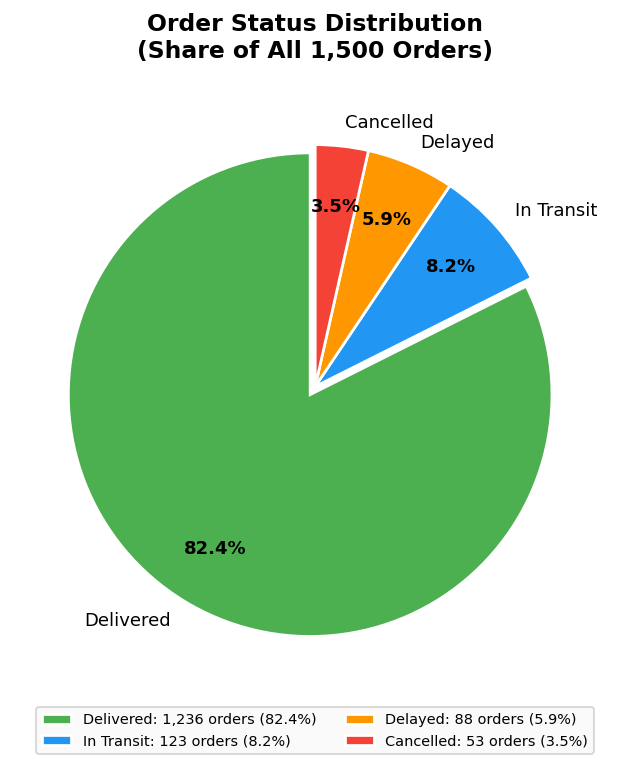

Chart saved → chart_4_1_standard_pie.png


In [ ]:
# ── Aggregate ────────────────────────────────────────────────────────────────
status_counts = df["Order Status"].value_counts()
status_order  = ["Delivered", "In Transit", "Delayed", "Cancelled"]
status_counts = status_counts.reindex(status_order)
status_colors_pie = ["#4CAF50", "#2196F3", "#FF9800", "#F44336"]

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 6))

wedges, texts, autotexts = ax.pie(
    status_counts.values,
    labels=status_counts.index,
    colors=status_colors_pie,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.75,
    wedgeprops={"edgecolor": "white", "linewidth": 1.5},
    explode=[0.04, 0, 0, 0],   # slightly explode the dominant slice
)
for text in autotexts:
    text.set_fontsize(10)
    text.set_fontweight("bold")
for text in texts:
    text.set_fontsize(10)

ax.set_title("Order Status Distribution\n(Share of All 1,500 Orders)", pad=15)

# Legend with absolute counts
legend_labels = [f"{s}: {c:,} orders ({c/status_counts.sum()*100:.1f}%)"
                 for s, c in zip(status_counts.index, status_counts.values)]
ax.legend(wedges, legend_labels, loc="lower center",
          bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=8)
plt.tight_layout()
plt.savefig("chart_4_1_standard_pie.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved → chart_4_1_standard_pie.png")

#### 📌 Interpretation
- **Delivered (82.4%)** dominates — the vast majority of orders reach the customer successfully.
- **In Transit (8.2%)** is next — orders that are still on the way.
- **Delayed (5.9%)** and **Cancelled (3.5%)** together make up less than 10% — supply chain problems are uncommon but not rare.
- **Why this chart?** Only 4 categories, all adding up to 100% of orders.
  The huge "Delivered" slice immediately tells the story — the supply chain is mostly healthy.
  A bar chart would give the same numbers but without the visual sense of "how big is this share."

### 4.2 Donut Chart
**Definition:** A Donut chart is a Pie chart with a **hole cut out of the center**.
The slices show the same proportional information, but the empty center can hold a
key number or label — making it both readable and informative.

**Why Donut?** Same use case as a standard pie, but the center space allows you to add
context (e.g., the total count or a headline metric). Many designers prefer it because
the hole reduces the visual weight and makes slice sizes slightly easier to compare.

**Data used:** Share of orders by **Transportation Mode** with total orders in the center.

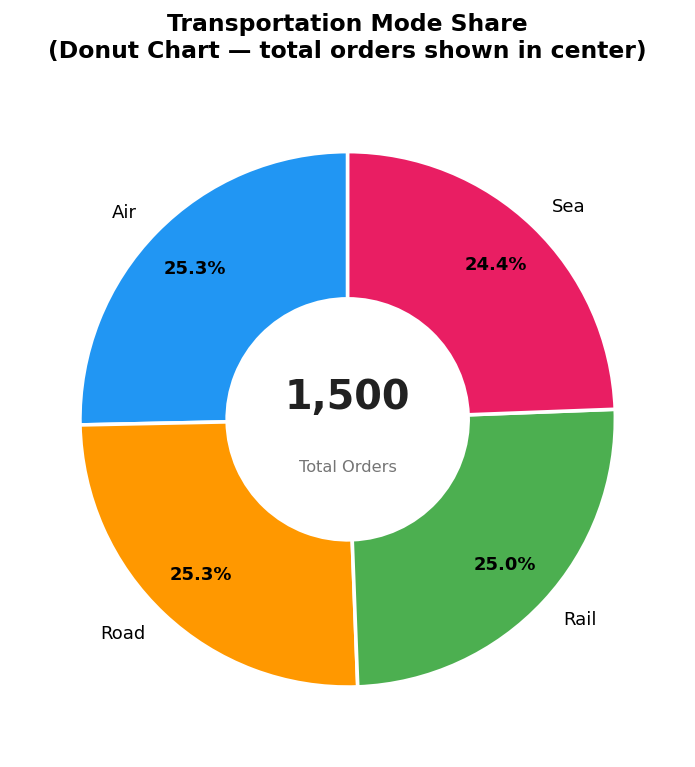

Chart saved → chart_4_2_donut.png


In [ ]:
# ── Aggregate ────────────────────────────────────────────────────────────────
mode_share = df["Transportation Mode"].value_counts()
total_orders = mode_share.sum()
mode_colors  = ["#2196F3", "#FF9800", "#4CAF50", "#E91E63"]

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 6))

wedges, texts, autotexts = ax.pie(
    mode_share.values,
    labels=mode_share.index,
    colors=mode_colors,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.80,
    wedgeprops={"edgecolor": "white", "linewidth": 2, "width": 0.55},  # width < 1 = donut
)
for text in autotexts:
    text.set_fontsize(10)
    text.set_fontweight("bold")
for text in texts:
    text.set_fontsize(10)

# Center label (what makes a donut unique)
ax.text(0, 0.08, f"{total_orders:,}", ha="center", va="center",
        fontsize=22, fontweight="bold", color="#212121")
ax.text(0, -0.18, "Total Orders", ha="center", va="center",
        fontsize=9, color="#757575")

ax.set_title("Transportation Mode Share\n(Donut Chart — total orders shown in center)", pad=15)
plt.tight_layout()
plt.savefig("chart_4_2_donut.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved → chart_4_2_donut.png")

#### 📌 Interpretation
- All four transportation modes carry roughly equal shares: **Air (25.3%), Road (25.3%), Rail (25.0%), Sea (24.4%)**.
- The supply chain is well-balanced — no single transportation mode dominates.
- **1,500 total orders** shown in the center gives the audience immediate context without cluttering the chart.
- **Why this chart vs. standard pie?** The center hole serves a purpose here: it shows the total order count
  right in the middle of the chart. This is a common business dashboard pattern. The story ("all modes are
  roughly equal") is the same as a standard pie, but the donut feels cleaner and adds the extra data point.

### 4.3 Sunburst Chart
**Definition:** A Sunburst chart is a **multi-level pie chart**. The inner ring shows the top-level
categories; the outer ring(s) show sub-categories inside each slice. It is used to visualise
**hierarchical (parent-child) data** in one circular view.

**Why Sunburst?** When your data has two or more levels of grouping (like Region → Countries,
or Category → Products) and you want to see both the parent size and the child breakdown at once.
A regular pie can only show one level.

**Data used:** **Product Category** (inner ring, 5 categories) → **Product Name** (outer ring, 25 products)
coloured by Total **Profit** so size = number of orders and colour = how profitable each product is.

In [ ]:
# ── Aggregate ────────────────────────────────────────────────────────────────
sun = (
    df.groupby(["Product Category", "Product Name"])
    .agg(Orders=("Order ID", "count"), Profit=("Profit", "sum"))
    .reset_index()
)

fig = px.sunburst(
    sun,
    path=["Product Category", "Product Name"],
    values="Orders",
    color="Profit",
    color_continuous_scale="RdYlGn",
    color_continuous_midpoint=sun["Profit"].median(),
    title="Product Hierarchy: Category → Product Name<br>"
          "<sup>Slice size = number of orders &nbsp;|&nbsp; Colour = total profit (green = high)</sup>",
)
fig.update_layout(
    height=580,
    margin=dict(t=90, b=20, l=20, r=20),
    coloraxis_colorbar=dict(title="Profit (USD)", tickformat="$,.0f"),
    font=dict(family="Arial", size=12),
)
fig.show()

#### 📌 Interpretation
- The **inner ring** shows the 5 Product Categories. **Electronics** and **Furniture** are the two
  largest slices — they handle the most orders.
- The **outer ring** shows each individual product within its category.
  For example, inside Electronics: `Power Bank`, `Smart Watch`, `Bluetooth Speaker`, `Router`, `Wireless Earbuds`.
- **Colour tells the profit story:** Green products (like `Office Chair` and `Study Table` in Furniture)
  are the most profitable. Products that appear red or yellow are lower-margin.
- **Why this chart?** A regular pie chart can only show one level (Category OR Product).
  A Sunburst shows both levels simultaneously and makes the hierarchy obvious.
  Clicking any segment in the interactive chart zooms into that category — powerful for a live presentation.

### 4.4 Polar Area Pie Chart
**Definition:** A Polar Area chart is similar to a standard pie chart but with one key difference:
all slices have the **same angle** (they span equal degrees). Instead, the **radius (distance from center)**
varies — a bigger radius means a bigger value. It combines the circular layout of a pie chart
with the length-based encoding of a bar chart.

**Why Polar Area?** When you have cyclic or time-based categories (like months of the year) and
want to show values in a circular layout where the shape itself suggests the cycle.
The audience can quickly see which months are "long" (high value) and which are "short" (low value).

**Data used:** Monthly **Total Profit** across all 12 months (combining 2024 and 2025 data)

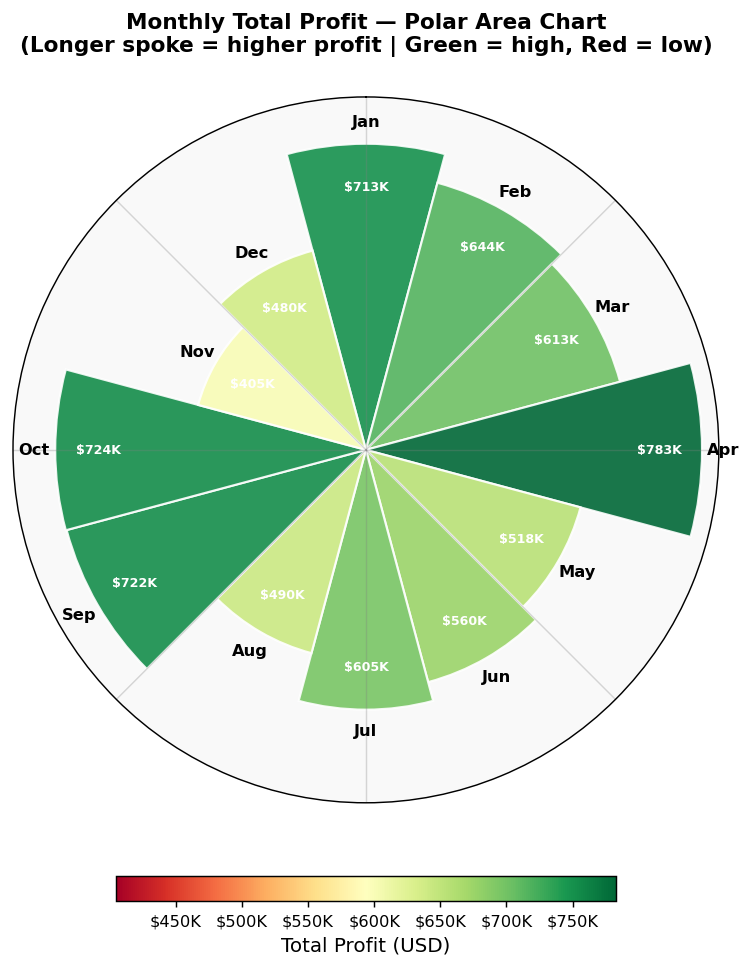

Chart saved → chart_4_4_polar_area.png


In [ ]:
# ── Aggregate ────────────────────────────────────────────────────────────────
month_profit = (
    df.groupby("Order Month")["Profit"]
    .sum()
    .reset_index()
)
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
month_profit["Month Name"] = month_profit["Order Month"].apply(lambda x: month_names[x-1])

# ── Build Polar Area using matplotlib polar projection ───────────────────────
N = 12
angles   = np.linspace(0, 2 * np.pi, N, endpoint=False)
values   = month_profit["Profit"].values
# Normalise radii for plotting (keep proportional to true values)
r_max    = values.max()
colors_polar = plt.cm.RdYlGn(values / r_max)

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
ax.set_theta_zero_location("N")     # 12 o'clock = first month
ax.set_theta_direction(-1)          # clockwise

width = 2 * np.pi / N               # equal angular width for each slice
bars = ax.bar(angles, values, width=width, bottom=0,
              color=colors_polar, edgecolor="white", linewidth=1.2, alpha=0.9)

# Month labels
for angle, label, val in zip(angles, month_names, values):
    ax.text(angle, val + 50_000, label,
            ha="center", va="center", fontsize=9, fontweight="bold")
    ax.text(angle, val - 100_000, f"${val/1e3:.0f}K",
            ha="center", va="center", fontsize=7, color="white", fontweight="bold")

ax.set_yticks([])                   # hide radial grid labels
ax.set_xticklabels([])              # hide default angle labels (we added our own)
ax.set_title("Monthly Total Profit — Polar Area Chart\n"
             "(Longer spoke = higher profit | Green = high, Red = low)",
             pad=25, fontsize=12, fontweight="bold")
ax.grid(color="grey", alpha=0.3)

# Colour bar legend
sm = plt.cm.ScalarMappable(cmap="RdYlGn", norm=plt.Normalize(values.min(), values.max()))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation="horizontal",
                    shrink=0.5, pad=0.08, label="Total Profit (USD)")
cbar.ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1e3:.0f}K"))

plt.tight_layout()
plt.savefig("chart_4_4_polar_area.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved → chart_4_4_polar_area.png")

#### 📌 Interpretation
- **April** has the longest spoke (\$783K profit) — the best month across both years.
- **January** (\$713K) and **September** (\$722K) are also high-profit months.
- **November** (\$405K) and **August** (\$490K) have the shortest spokes — weakest months.
- The circular layout makes the **seasonal cycle** immediately visible — the chart literally
  "completes a year" as you go around the circle.
- **Why this chart?** Months are cyclic — December connects back to January. A circular layout
  respects that cycle in a way a straight bar chart cannot. The equal-angle, variable-radius design
  lets us compare 12 months simultaneously without any bars overlapping.
  A standard pie chart would show the same numbers but its varying angles would be harder to read.

---
## ✅ Section 5 — Conclusion

### Key Takeaway: Choosing the Right Chart
The goal of data visualization is not to draw "any chart" — it is to **pick the right chart
for the right data and the right question**. Here is a quick summary of what we learned:

| Chart Type | Use When | Example in This Notebook |
|---|---|---|
| **Vertical Bar** | Few short-named categories, compare values | Profit by Product Category |
| **Horizontal Bar** | Many or long-named categories | Orders by Customer Country (27 countries) |
| **Grouped Bar** | Two categorical dimensions, side-by-side comparison | Delivery Time by Mode × Category |
| **Stacked Bar** | Show totals AND breakdown at once | Profit by Region stacked by Category |
| **100% Stacked Bar** | Compare proportions, totals don't matter | Order Status share by Transport Mode |
| **Waterfall** | Show step-by-step change between two values | 2024 → 2025 Profit Bridge |
| **Histogram** | Understand the distribution/shape of one numeric variable | Delivery Time (Days) |
| **Standard Pie** | Show parts of a whole, few slices (≤ 6) | Order Status split |
| **Donut** | Same as pie, but center holds a key number | Transport Mode share |
| **Sunburst** | Multi-level hierarchy (parent → child) | Category → Product Name |
| **Polar Area** | Cyclic categories (months/seasons) + magnitude difference | Monthly Profit |

---

### Why Answer "Why This Chart?"
> *A chart without a reason is just decoration.*

Throughout this notebook, every chart answers three questions:
1. **What is this chart?** — the definition
2. **What does it show?** — the data interpretation
3. **Why this chart for this data?** — the justification

That is the core skill of data visualization: not drawing charts, but **choosing the right one**.

---
*Dataset: SupplyChain Dataset.csv — 1,500 orders, 24 columns, 2024–2025*
*Tools: Python 3 · pandas · NumPy · Matplotlib · Seaborn · Plotly*